<a href="https://colab.research.google.com/github/ihsann2410010447/projek-statistika-Akbar-Ihsan-Nugraha/blob/main/Milestone5_Dua_Sampel_ChiSquare_2410010447_Akbar_Ihsan_Nugraha.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📝 Milestone 5 — Uji Hipotesis Dua Sampel & Chi-Square

**Mata Kuliah:** Statistika & Probabilitas (TIF1501) · CPMK072 (Sub-CPMK 072.2) · Milestone 5
**Nama / NIM:** _isi di sini_
**Dataset:** _nama dataset Milestone 1–4 Anda_

> **Cara pakai:** (1) isi sel **Konfigurasi** (nama kolom & grup yang dibandingkan), (2) jalankan semua sel, (3) tulis interpretasi di sel markdown bertanda `_..._`, (4) susun README yang merangkum seluruh temuan Milestone 1–5.
> Secara default notebook memakai **data demo sintetis** agar langsung bisa dijalankan — ganti `DATA_PATH` untuk memakai dataset Anda.

### Empat komponen
1. **Numerik × 2 grup** — Welch t-test (default) atau Mann-Whitney U bila data sangat skewed; lengkap dengan CI & effect size.
2. **Kategorik × kategorik** — chi-square independensi + residual terstandar + Cramér's V; Fisher exact bila tabel 2×2 punya sel kecil.
3. **Dua proporsi** *atau* **data berpasangan** (sesuai desain data Anda).
4. **Diskusi asosiasi vs sebab-akibat** — stratifikasi untuk menguji peran confounder.

> ⚖️ **Catatan etis:** membandingkan kelompok (mis. gender, wilayah, perangkat) menggambarkan **pola pada data**, bukan kemampuan individu — dan bukan bukti sebab-akibat.

# 🔧 1. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest

sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)
rng = np.random.default_rng(42)
ALPHA = 0.05

# ⚙️ 2. Konfigurasi & Load Data

Pilih **perbandingan yang bermakna** dari insight Milestone 1–4. Isi `None` pada bagian yang datanya tidak ada (mis. tidak ada data berpasangan) — bagian itu akan dilewati.

| Bagian | Parameter |
|---|---|
| 1. Numerik × 2 grup | `COL_NUM`, `COL_GRP`, `GA`, `GB` |
| 2. Chi-square | `COL_CAT1`, `COL_CAT2`, `MIN_N_KATEGORI` (gabungkan kategori dengan n < ini menjadi "Lainnya"; 0 = tidak digabung) |
| 3a. Dua proporsi | `COL_PROP_GRP`, `GP1`, `GP2`, `COL_OUT`, `SUKSES` |
| 3b. Berpasangan | `COL_BEFORE`, `COL_AFTER` (dua kolom pada baris yang sama = satu subjek) |
| 4. Confounder | `COL_CONFOUNDER`, `STRATA_OUTCOME` (numerik atau 0/1) |

In [2]:
# ====== ISI BAGIAN INI ======
DATA_PATH = None   # contoh: "https://raw.githubusercontent.com/.../data.csv" atau "data.csv"

# --- 1. NUMERIK × 2 GRUP ---
COL_NUM, COL_GRP, GA, GB = "belanja", "perangkat", "iOS", "Android"     # selisih dihitung GA − GB

# --- 2. KATEGORIK × KATEGORIK ---
COL_CAT1, COL_CAT2 = "segmen", "wilayah"
MIN_N_KATEGORI = 0

# --- 3a. DUA PROPORSI (None bila tidak dipakai) ---
COL_PROP_GRP, GP1, GP2 = "perangkat", "iOS", "Android"
COL_OUT, SUKSES = "repeat", 1

# --- 3b. BERPASANGAN (None bila tidak ada data berpasangan) ---
COL_BEFORE, COL_AFTER = "skor_sebelum", "skor_sesudah"

# --- 4. CONFOUNDER ---
COL_CONFOUNDER = "wilayah"        # variabel yang mungkin memengaruhi grup DAN hasil
STRATA_OUTCOME = "repeat"         # hasil yang dibandingkan antar grup (numerik atau 0/1)
# ============================

if DATA_PATH:
    df_my = pd.read_csv(DATA_PATH)
else:
    print("⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).")
    n_demo = 600
    perangkat = rng.choice(["iOS", "Android"], n_demo, p=[0.4, 0.6])
    kota = np.where(perangkat == "iOS", rng.random(n_demo) < 0.80, rng.random(n_demo) < 0.50)   # iOS lebih banyak di kota
    wilayah = np.where(kota, "Kota", "Desa")
    belanja = rng.lognormal(3.0 + 0.25 * (perangkat == "iOS") + 0.2 * kota, 0.9, n_demo).round(2)
    repeat = rng.binomial(1, 0.20 + 0.12 * kota + 0.02 * (perangkat == "iOS"))
    segmen = np.array([rng.choice(["Baru", "Reguler", "Premium"], p=([0.3, 0.4, 0.3] if k else [0.5, 0.4, 0.1])) for k in kota])
    sebelum = rng.normal(70, 10, n_demo); sesudah = sebelum + rng.normal(3, 4, n_demo)
    df_my = pd.DataFrame({"perangkat": perangkat, "wilayah": wilayah, "segmen": segmen, "belanja": belanja, "repeat": repeat,
                          "skor_sebelum": np.where(np.arange(n_demo) < 40, sebelum, np.nan),     # hanya 40 subjek punya data berpasangan
                          "skor_sesudah": np.where(np.arange(n_demo) < 40, sesudah, np.nan)})

print(f"Shape: {df_my.shape[0]:,} baris × {df_my.shape[1]} kolom")
df_my.head()

⚠️ DATA_PATH kosong → memakai DATA DEMO sintetis (bukan data Anda).
Shape: 600 baris × 7 kolom


,perangkat,wilayah,segmen,belanja,repeat,skor_sebelum,skor_sesudah
0,Android,Desa,Baru,154.61,0,54.143966,58.570817
1,Android,Desa,Baru,7.94,0,60.795442,66.782830
2,Android,Desa,Reguler,21.40,1,85.682064,88.329083
3,Android,Desa,Baru,6.97,0,73.847233,80.887488
4,iOS,Desa,Reguler,12.81,1,56.764117,58.546876


# 🧰 3. Fungsi Bantu

In [3]:
RESULTS = []   # untuk tabel ringkasan


def _catat(nama, uji, p, effect, ci_txt="—"):
    RESULTS.append([nama, uji, p, effect, ci_txt, "Tolak H₀" if p < ALPHA else "Gagal tolak H₀"])


# ---------- Effect size (identik dengan Modul 13) ----------
def cohens_d(a, b):
    """Selisih mean dalam satuan pooled standard deviation."""
    a, b = np.asarray(a), np.asarray(b)
    sp = np.sqrt(((len(a)-1)*a.var(ddof=1) + (len(b)-1)*b.var(ddof=1)) / (len(a)+len(b)-2))
    return (a.mean() - b.mean()) / sp

def welch_ci(a, b, alpha=ALPHA):
    """CI selisih mean dengan derajat bebas Welch-Satterthwaite."""
    va, vb = np.var(a, ddof=1)/len(a), np.var(b, ddof=1)/len(b)
    df = (va + vb)**2 / (va**2/(len(a)-1) + vb**2/(len(b)-1))
    diff, se = np.mean(a) - np.mean(b), np.sqrt(va + vb)
    t = stats.t.ppf(1 - alpha/2, df)
    return diff, diff - t*se, diff + t*se

def cramers_v(table):
    chi2 = stats.chi2_contingency(table, correction=False)[0]
    n = np.asarray(table).sum()
    return np.sqrt(chi2 / (n * (min(np.asarray(table).shape) - 1)))

def prob_superiority(a, b):
    """P(X > Y) + 0.5·P(X = Y) — effect size untuk Mann-Whitney (0.5 = tidak ada beda)."""
    u = stats.mannwhitneyu(a, b).statistic
    return u / (len(a) * len(b))


# ---------- 1. Numerik × 2 grup independen ----------
def uji_numerik_2grup(df, num, grp, ga, gb, nama=None, boot=1000):
    nama = nama or f"{num}: {ga} vs {gb}"
    a = df.loc[df[grp] == ga, num].dropna().astype(float)
    b = df.loc[df[grp] == gb, num].dropna().astype(float)
    print(f"=== {nama} ===")
    desc = pd.DataFrame({ga: [len(a), a.mean(), a.median(), a.std(), stats.skew(a)],
                         gb: [len(b), b.mean(), b.median(), b.std(), stats.skew(b)]},
                        index=["n", "mean", "median", "sd", "skewness"]).round(3)
    print(desc.to_string())
    # -- asumsi
    sw = [stats.shapiro(g.sample(min(len(g), 500), random_state=0)).pvalue for g in (a, b)]
    lev = stats.levene(a, b).pvalue
    print(f"\nAsumsi: Shapiro p = {sw[0]:.3g} / {sw[1]:.3g} | Levene p = {lev:.4f} (varians {'sama' if lev > ALPHA else 'berbeda'} → Welch aman di keduanya)")
    strong_skew = max(abs(stats.skew(a)), abs(stats.skew(b))) > 1
    small_nonnormal = min(len(a), len(b)) < 30 and min(sw) < ALPHA
    # -- Welch t-test (default)
    tw = stats.ttest_ind(a, b, equal_var=False)
    diff, lo, hi = welch_ci(a, b); d = cohens_d(a, b)
    print(f"\nWelch t-test : t = {tw.statistic:.3f}, p = {tw.pvalue:.4g}")
    print(f"Selisih mean ({ga} − {gb}) = {diff:+.4f}, CI 95% [{lo:+.4f}, {hi:+.4f}], Cohen's d = {d:.3f} (0.2 kecil · 0.5 sedang · 0.8 besar)")
    # -- Mann-Whitney bila data sangat skewed / sampel kecil tak normal
    if strong_skew or small_nonnormal:
        why = "data sangat skewed (|skew| > 1)" if strong_skew else "n < 30 dan tidak normal"
        mw = stats.mannwhitneyu(a, b, alternative="two-sided"); ps = prob_superiority(a, b)
        a_, b_ = a.values, b.values
        bd = np.array([np.median(a_[rng.integers(0, len(a_), len(a_))]) - np.median(b_[rng.integers(0, len(b_), len(b_))]) for _ in range(boot)])
        mlo, mhi = np.percentile(bd, [2.5, 97.5])
        print(f"\n⚠️ {why} → uji UTAMA: Mann-Whitney U")
        print(f"Mann-Whitney : U = {mw.statistic:,.0f}, p = {mw.pvalue:.4g}")
        print(f"P(X > Y) = {ps:.3f} (0.50 = tidak ada beda)  |  selisih median = {np.median(a_) - np.median(b_):+.4f}, CI bootstrap 95% [{mlo:+.4f}, {mhi:+.4f}]")
        _catat(nama, "Mann-Whitney U", mw.pvalue, f"P(X>Y) = {ps:.2f}", f"Δmedian [{mlo:+.3g}, {mhi:+.3g}]")
        p = mw.pvalue
    else:
        print("\n✅ Tidak ada indikasi pelanggaran berat → uji UTAMA: Welch t-test")
        _catat(nama, "Welch t-test", tw.pvalue, f"d = {d:.2f}", f"Δmean [{lo:+.3g}, {hi:+.3g}]")
        p = tw.pvalue
    print(f"Keputusan (α = {ALPHA}): {'TOLAK H₀' if p < ALPHA else 'GAGAL TOLAK H₀'}\n")

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    cut = pd.concat([a, b]).quantile(0.99)
    for lbl, g, c in [(ga, a, "#4338CA"), (gb, b, "#BE123C")]:
        axes[0].hist(g[g <= cut], bins=40, alpha=0.55, color=c, density=True, label=lbl)
    axes[0].set_title(f"Distribusi {num} (≤ persentil 99)", fontweight="bold"); axes[0].legend()
    axes[1].errorbar([0, 1], [a.mean(), b.mean()], yerr=[1.96 * stats.sem(a), 1.96 * stats.sem(b)], fmt="o", capsize=8, color="black")
    axes[1].set_xticks([0, 1]); axes[1].set_xticklabels([ga, gb]); axes[1].set_xlim(-0.5, 1.5)
    axes[1].set_title("Mean ± CI 95%", fontweight="bold")
    plt.tight_layout(); plt.show()
    return p


# ---------- 2. Kategorik × kategorik ----------
def gabung_jarang(s, min_n):
    vc = s.value_counts(); rare = vc[vc < min_n].index
    return s.where(~s.isin(rare), "Lainnya")


def uji_chi2(df, c1, c2, nama=None, min_n=0):
    nama = nama or f"{c1} × {c2}"
    s1, s2 = df[c1], df[c2]
    if min_n:
        s1, s2 = gabung_jarang(s1, min_n), gabung_jarang(s2, min_n)
    tab = pd.crosstab(s1, s2)
    if tab.shape[0] < 2 or tab.shape[1] < 2:
        print(f"⚠️ Tabel hanya {tab.shape[0]}×{tab.shape[1]} (setelah penggabungan 'Lainnya') — chi-square tidak dapat dihitung.")
        print("   Turunkan MIN_N_KATEGORI atau pilih variabel lain.\n")
        return np.nan
    chi2, p, dof, exp = stats.chi2_contingency(tab)
    V = cramers_v(tab); frac_low = (exp < 5).mean()
    resid = (tab - exp) / np.sqrt(exp)
    print(f"=== CHI-SQUARE INDEPENDENSI: {nama} ===")
    print("Observed:"); print(tab)
    print(f"\nExpected minimum = {exp.min():.2f}, sel dengan expected < 5 = {frac_low:.0%}")
    p_use, uji, eff = p, "Chi-square", f"V = {V:.2f}"
    if tab.shape == (2, 2) and exp.min() < 5:
        fe = stats.fisher_exact(tab.values)
        p_use, uji, eff = fe[1], "Fisher exact", f"OR = {fe[0]:.2f}"
        print(f"⚠️ Tabel 2×2 dengan expected < 5 → uji UTAMA: Fisher exact (OR = {fe[0]:.3f}, p = {fe[1]:.4g}); chi-square p = {p:.4g} hanya pembanding")
    elif exp.min() < 5 or frac_low > 0.2:
        print("⚠️ Syarat chi-square dilanggar (expected < 5). Gabungkan kategori jarang (ubah MIN_N_KATEGORI) sebelum menyimpulkan.")
        print(f"   χ² = {chi2:.2f}, dof = {dof}, p = {p:.4g} — TIDAK dapat diandalkan.")
    else:
        print(f"✅ Syarat terpenuhi. χ² = {chi2:,.2f}, dof = {dof}, p = {p:.4g}")
    print(f"Cramér's V = {V:.3f} (0.1 lemah · 0.3 sedang · 0.5 kuat)")
    print(f"Keputusan (α = {ALPHA}): {'TOLAK H₀ — ada hubungan' if p_use < ALPHA else 'GAGAL TOLAK H₀ — tidak ada bukti hubungan'}")
    notable = [(i, j, resid.loc[i, j]) for i in resid.index for j in resid.columns if abs(resid.loc[i, j]) > 2]
    if notable:
        print("Sel menonjol (|residual| > 2):")
        for i, j, r in sorted(notable, key=lambda t: -abs(t[2]))[:6]:
            print(f"   {c1}={i} × {c2}={j}: {r:+.1f} → {'LEBIH banyak' if r > 0 else 'LEBIH sedikit'} dari harapan jika independen")
    print()
    if tab.shape[0] <= 12 and tab.shape[1] <= 12:
        fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
        (pd.crosstab(s1, s2, normalize="index") * 100).plot(kind="barh", stacked=True, ax=axes[0], edgecolor="black")
        axes[0].set_xlabel("%"); axes[0].set_title(f"Komposisi {c2} per {c1}", fontweight="bold"); axes[0].invert_yaxis()
        sns.heatmap(resid, annot=True, fmt=".1f", cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "residual terstandar"})
        axes[1].set_title("Residual terstandar (O − E)/√E — |r| > 2 menonjol", fontweight="bold")
        plt.tight_layout(); plt.show()
    _catat(nama, uji, p_use, eff)
    return p_use


# ---------- 3a. Dua proporsi ----------
def uji_dua_proporsi(df, grp, g1, g2, out, sukses=1, nama=None):
    nama = nama or f"proporsi {out}={sukses}: {g1} vs {g2}"
    d = df[[grp, out]].dropna()
    ok1, ok2 = (d.loc[d[grp] == g1, out] == sukses), (d.loc[d[grp] == g2, out] == sukses)
    k, n = np.array([ok1.sum(), ok2.sum()]), np.array([len(ok1), len(ok2)])
    p1, p2 = k / n; diff = p1 - p2
    se = np.sqrt(p1 * (1 - p1) / n[0] + p2 * (1 - p2) / n[1]); zc = stats.norm.ppf(1 - ALPHA / 2)
    print(f"=== {nama} ===")
    print(f"  {g1}: {k[0]:,}/{n[0]:,} = {p1:.2%}   |   {g2}: {k[1]:,}/{n[1]:,} = {p2:.2%}")
    print(f"  Selisih = {diff*100:+.2f} poin persen, CI 95% [{(diff - zc*se)*100:+.2f}, {(diff + zc*se)*100:+.2f}]")
    if min(k.min(), (n - k).min()) < 10:
        fe = stats.fisher_exact([[k[0], n[0] - k[0]], [k[1], n[1] - k[1]]])
        p, uji = fe[1], "Fisher exact"
        print(f"  ⚠️ Ada sel < 10 → uji UTAMA: Fisher exact, OR = {fe[0]:.3f}, p = {p:.4g}")
        eff = f"OR = {fe[0]:.2f}"
    else:
        z, p = proportions_ztest(k, n); uji = "z dua proporsi"
        print(f"  z = {z:.3f}, p = {p:.4g}")
        if p1 > 0 and p2 > 0:
            rr = p1 / p2; se_l = np.sqrt((1 - p1) / k[0] + (1 - p2) / k[1])
            print(f"  Relative risk = {rr:.3f}, CI 95% [{np.exp(np.log(rr) - zc*se_l):.3f}, {np.exp(np.log(rr) + zc*se_l):.3f}]  → proporsi {g1} = {rr:.2f}× proporsi {g2}")
            eff = f"RR = {rr:.2f}"
        else:
            eff = f"Δ = {diff*100:+.1f} poin"
    print(f"  Keputusan (α = {ALPHA}): {'TOLAK H₀' if p < ALPHA else 'GAGAL TOLAK H₀'}\n")
    _catat(nama, uji, p, eff, f"Δ [{(diff - zc*se)*100:+.1f}, {(diff + zc*se)*100:+.1f}] poin")
    return p


# ---------- 3b. Berpasangan ----------
def uji_berpasangan(df, before, after, nama=None):
    nama = nama or f"{after} vs {before} (berpasangan)"
    d = df[[before, after]].dropna(); x, y = d[before], d[after]; diff = y - x; n = len(diff)
    sw = stats.shapiro(diff).pvalue if n >= 3 else np.nan
    print(f"=== {nama} (n pasangan = {n}) ===")
    print(f"  mean {before} = {x.mean():.3f}, mean {after} = {y.mean():.3f}, d̄ = {diff.mean():+.3f}, s_d = {diff.std(ddof=1):.3f}")
    print(f"  Korelasi {before}–{after}: r = {np.corrcoef(x, y)[0, 1]:.2f}  | Shapiro pada SELISIH: p = {sw:.3g}")
    tp = stats.ttest_rel(y, x)
    ci = stats.t.interval(1 - ALPHA, n - 1, loc=diff.mean(), scale=stats.sem(diff)); dz = diff.mean() / diff.std(ddof=1)
    print(f"  Paired t-test: t = {tp.statistic:.3f}, p = {tp.pvalue:.4g}, CI d̄ [{ci[0]:+.3f}, {ci[1]:+.3f}], d_z = {dz:.3f}")
    try: wp = stats.wilcoxon(y, x).pvalue
    except ValueError: wp = np.nan
    print(f"  Wilcoxon signed-rank: p = {wp:.4g}")
    ind = stats.ttest_ind(y, x, equal_var=False)
    print(f"  ❌ [pembanding, SALAH desain] uji independen: p = {ind.pvalue:.4g} — mencampur variasi ANTAR orang ke dalam noise")
    use_wilcoxon = n < 30 and sw < ALPHA
    p, uji = (wp, "Wilcoxon signed-rank") if use_wilcoxon else (tp.pvalue, "Paired t-test")
    print(f"  ➜ Uji UTAMA: {uji}" + (" (n < 30 dan selisih tidak normal)" if use_wilcoxon else ""))
    print(f"  Keputusan (α = {ALPHA}): {'TOLAK H₀' if p < ALPHA else 'GAGAL TOLAK H₀'}\n")
    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    if n <= 60:
        for a_, b_ in zip(x, y): axes[0].plot([0, 1], [a_, b_], "o-", color="#4338CA", alpha=0.45)
        axes[0].set_xticks([0, 1]); axes[0].set_xticklabels([before, after]); axes[0].set_title("Satu garis = satu subjek", fontweight="bold")
    else:
        axes[0].scatter(x, y, alpha=0.4); lim = [min(x.min(), y.min()), max(x.max(), y.max())]; axes[0].plot(lim, lim, "r--")
        axes[0].set_xlabel(before); axes[0].set_ylabel(after); axes[0].set_title("Di atas garis merah = naik", fontweight="bold")
    axes[1].hist(diff, bins=20, color="#059669", edgecolor="black", alpha=0.8); axes[1].axvline(0, color="black"); axes[1].axvline(diff.mean(), color="#BE123C", ls="--", label=f"d̄ = {diff.mean():.2f}")
    axes[1].set_title("Distribusi selisih", fontweight="bold"); axes[1].legend()
    plt.tight_layout(); plt.show()
    _catat(nama, uji, p, f"d̄ = {diff.mean():+.2f}", f"[{ci[0]:+.3g}, {ci[1]:+.3g}]")
    return p


# ---------- 4. Stratifikasi (confounder) ----------
def stratifikasi(df, outcome, grp, g1, g2, conf, min_n=20, bins=4):
    d = df[[outcome, grp, conf]].dropna(); d = d[d[grp].isin([g1, g2])].copy()
    c = d[conf]
    if pd.api.types.is_numeric_dtype(c) and c.nunique() > 8:
        codes, edges = pd.qcut(c, bins, labels=False, retbins=True, duplicates="drop")
        c = codes.map(lambda i: f"Q{int(i)+1} ({edges[int(i)]:.3g}–{edges[int(i)+1]:.3g})")   # urut Q1..Qn
    d["_s"] = c.astype(str)
    binary = set(d[outcome].unique()) <= {0, 1}; mult = 100 if binary else 1; unit = "poin persen" if binary else "satuan"
    tot1, tot2 = (d[grp] == g1).sum(), (d[grp] == g2).sum()
    rows = []
    for s, g in d.groupby("_s"):
        a, b = g.loc[g[grp] == g1, outcome], g.loc[g[grp] == g2, outcome]
        if len(a) >= min_n and len(b) >= min_n:
            rows.append([s, len(a) / tot1 * 100, len(b) / tot2 * 100, a.mean() * mult, b.mean() * mult, (a.mean() - b.mean()) * mult, len(a) + len(b)])
    tab = pd.DataFrame(rows, columns=["strata", f"% {g1} di strata", f"% {g2} di strata", f"rata-rata {g1}", f"rata-rata {g2}", "selisih", "n"])
    if tab.empty:
        print(f"⚠️ Tidak ada strata '{conf}' dengan ≥ {min_n} data di KEDUA grup — stratifikasi tidak dapat dihitung.")
        print("   Turunkan min_n, kurangi jumlah strata (mis. gabungkan kategori), atau kumpulkan data lebih banyak.\n")
        return tab, np.nan, np.nan
    crude = (d.loc[d[grp] == g1, outcome].mean() - d.loc[d[grp] == g2, outcome].mean()) * mult
    adj = np.average(tab["selisih"], weights=tab["n"])
    print(f"=== STRATIFIKASI: {outcome} ({g1} − {g2}) per strata '{conf}' ===")
    print(tab.drop(columns="n").round(2).to_string(index=False))
    print(f"\nSelisih KASAR (tanpa strata)      = {crude:+.2f} {unit}")
    print(f"Selisih TERSTRATIFIKASI (rata-rata berbobot) = {adj:+.2f} {unit}")
    if np.sign(crude) != np.sign(adj) and abs(adj) > 0:
        msg = "🚨 Tanda selisih BERBALIK setelah strata (Simpson's paradox) — confounder sangat berpengaruh."
    elif abs(crude) > 0 and (abs(crude) - abs(adj)) / abs(crude) > 0.3:
        msg = f"⚠️ Selisih menyusut {(abs(crude)-abs(adj))/abs(crude):.0%} setelah strata → '{conf}' kemungkinan confounder penting."
    else:
        msg = f"Selisih relatif stabil setelah strata '{conf}' (tetap saja: confounder lain mungkin ada)."
    print(msg); print("Ingat: ini ASOSIASI. Klaim sebab-akibat butuh desain eksperimen / analisis kausal.\n")
    return tab, crude, adj


def ringkasan():
    t = pd.DataFrame(RESULTS, columns=["Perbandingan", "Uji", "p-value", "Effect size", "CI", "Keputusan (α=0.05)"])
    t["p-value"] = t["p-value"].map(lambda v: f"{v:.2e}" if v < 0.001 else f"{v:.4f}")
    return t

# 📊 4. Komponen 1 — Numerik × 2 Grup Independen

- **H₀:** rata-rata (atau distribusi) `COL_NUM` sama pada kedua grup
- **H₁:** berbeda

Fungsi memeriksa asumsi lalu memilih uji utama: **Welch t-test** secara default (aman walau varians berbeda); beralih ke **Mann-Whitney U** bila data sangat skewed (|skew| > 1) atau n < 30 dan tidak normal. Selalu dilaporkan: CI selisih dan effect size.

> Catatan: dengan n besar hampir semua perbandingan "signifikan" — **effect size yang membedakan seberapa penting**.

=== belanja: iOS vs Android ===
              iOS  Android
n         238.000  362.000
mean       41.944   32.684
median     30.425   22.525
sd         44.780   38.031
skewness    3.529    3.605

Asumsi: Shapiro p = 3.62e-21 / 4.22e-27 | Levene p = 0.0634 (varians sama → Welch aman di keduanya)

Welch t-test : t = 2.627, p = 0.008898
Selisih mean (iOS − Android) = +9.2600, CI 95% [+2.3337, +16.1863], Cohen's d = 0.227 (0.2 kecil · 0.5 sedang · 0.8 besar)

⚠️ data sangat skewed (|skew| > 1) → uji UTAMA: Mann-Whitney U
Mann-Whitney : U = 51,009, p = 0.0001347
P(X > Y) = 0.592 (0.50 = tidak ada beda)  |  selisih median = +7.9000, CI bootstrap 95% [+2.9286, +12.1320]
Keputusan (α = 0.05): TOLAK H₀



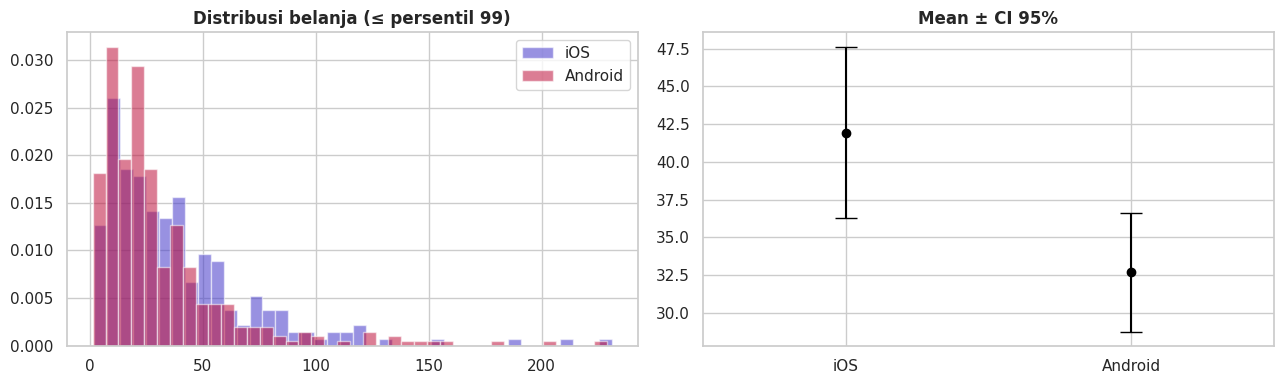

In [4]:
p_num = uji_numerik_2grup(df_my, COL_NUM, COL_GRP, GA, GB, nama=f"{COL_NUM}: {GA} vs {GB}")

**Interpretasi (tulis sendiri):**
- _Statistik:_ uji yang dipakai & alasannya (asumsi apa yang dicek?), p = ..., CI selisih = [..., ...], effect size = ...
- _Praktis:_ _apakah selisih sebesar itu penting bagi keputusan bisnis?_

# 🧮 5. Komponen 2 — Kategorik × Kategorik (Chi-Square Independensi)

- **H₀:** `COL_CAT1` independen dari `COL_CAT2`
- **H₁:** ada hubungan

Syarat: expected ≥ 5 pada (hampir) semua sel. Bila 2×2 dan syarat dilanggar → **Fisher exact**. Bila tabel lebih besar → gabungkan kategori jarang (`MIN_N_KATEGORI`). **Residual terstandar** (O−E)/√E menunjukkan *sel mana* yang menyimpang: |r| > 2 menonjol.

=== CHI-SQUARE INDEPENDENSI: segmen × wilayah ===
Observed:
wilayah  Desa  Kota
segmen             
Baru      115   102
Premium    21   119
Reguler    90   153

Expected minimum = 52.73, sel dengan expected < 5 = 0%
✅ Syarat terpenuhi. χ² = 52.39, dof = 2, p = 4.197e-12
Cramér's V = 0.296 (0.1 lemah · 0.3 sedang · 0.5 kuat)
Keputusan (α = 0.05): TOLAK H₀ — ada hubungan
Sel menonjol (|residual| > 2):
   segmen=Premium × wilayah=Desa: -4.4 → LEBIH sedikit dari harapan jika independen
   segmen=Baru × wilayah=Desa: +3.7 → LEBIH banyak dari harapan jika independen
   segmen=Premium × wilayah=Kota: +3.4 → LEBIH banyak dari harapan jika independen
   segmen=Baru × wilayah=Kota: -2.9 → LEBIH sedikit dari harapan jika independen



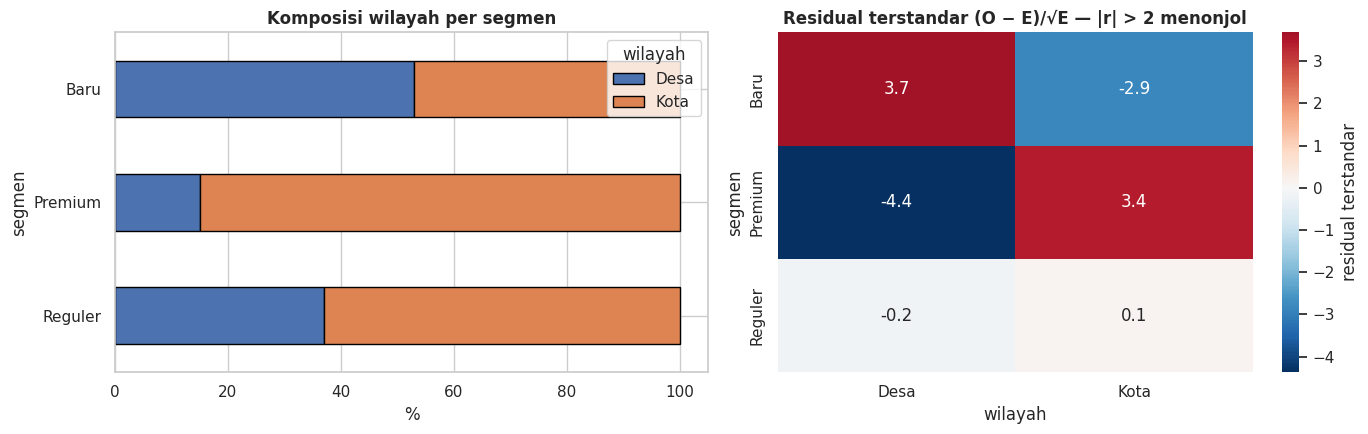

In [5]:
p_chi = uji_chi2(df_my, COL_CAT1, COL_CAT2, min_n=MIN_N_KATEGORI)

**Interpretasi (tulis sendiri):**
- _Statistik:_ χ² / Fisher, p = ..., Cramér's V = ... (lemah/sedang/kuat).
- _Sel yang menonjol:_ _kombinasi mana yang lebih/kurang dari harapan, dan apa artinya secara bisnis?_

# 🎯 6. Komponen 3 — Dua Proporsi **atau** Data Berpasangan

Pilih sesuai desain data. **Jangan memakai uji independen untuk data berpasangan** — variasi antar subjek akan menenggelamkan efeknya.

## 6a. Uji dua proporsi independen
- **H₀:** p₁ = p₂  **H₁:** p₁ ≠ p₂ — dengan CI selisih dan relative risk (Fisher exact bila sel < 10).

In [6]:
if COL_PROP_GRP and COL_OUT:
    p_prop = uji_dua_proporsi(df_my, COL_PROP_GRP, GP1, GP2, COL_OUT, SUKSES)
else:
    print("Bagian 6a dilewati (COL_PROP_GRP / COL_OUT = None).")

=== proporsi repeat=1: iOS vs Android ===
  iOS: 83/238 = 34.87%   |   Android: 87/362 = 24.03%
  Selisih = +10.84 poin persen, CI 95% [+3.36, +18.33]
  z = 2.883, p = 0.003941
  Relative risk = 1.451, CI 95% [1.127, 1.868]  → proporsi iOS = 1.45× proporsi Android
  Keputusan (α = 0.05): TOLAK H₀



## 6b. Uji berpasangan (sebelum–sesudah / dua pengukuran pada subjek yang sama)
- **H₀:** μ_d = 0  **H₁:** μ_d ≠ 0, dengan d = sesudah − sebelum. Uji utama: paired t-test; Wilcoxon signed-rank bila n < 30 dan selisih tidak normal.

=== skor_sesudah vs skor_sebelum (berpasangan) (n pasangan = 40) ===
  mean skor_sebelum = 69.805, mean skor_sesudah = 73.180, d̄ = +3.374, s_d = 4.263
  Korelasi skor_sebelum–skor_sesudah: r = 0.92  | Shapiro pada SELISIH: p = 0.306
  Paired t-test: t = 5.006, p = 1.23e-05, CI d̄ [+2.011, +4.737], d_z = 0.791
  Wilcoxon signed-rank: p = 6.357e-06
  ❌ [pembanding, SALAH desain] uji independen: p = 0.1391 — mencampur variasi ANTAR orang ke dalam noise
  ➜ Uji UTAMA: Paired t-test
  Keputusan (α = 0.05): TOLAK H₀



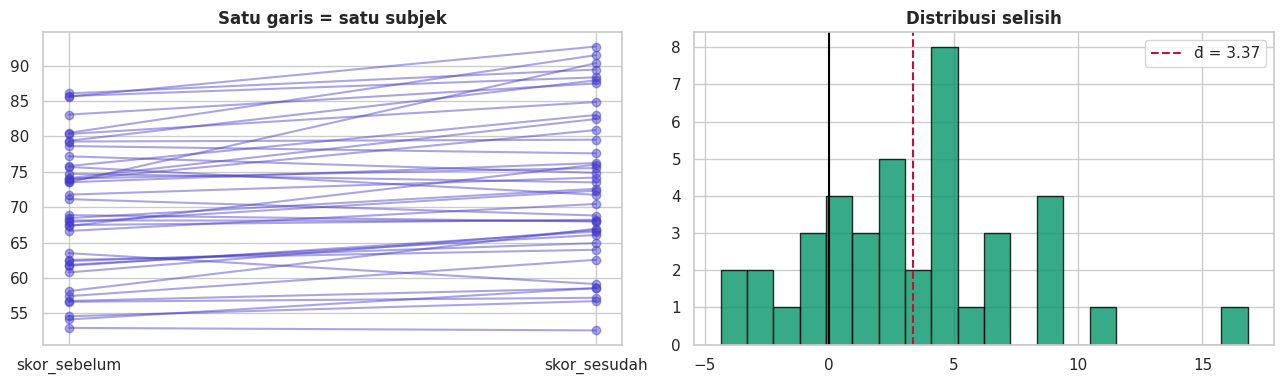

In [7]:
if COL_BEFORE and COL_AFTER:
    p_pair = uji_berpasangan(df_my, COL_BEFORE, COL_AFTER)
else:
    print("Bagian 6b dilewati (COL_BEFORE / COL_AFTER = None) — dataset tidak punya data berpasangan.")

**Interpretasi (tulis sendiri):** _Mengapa desain yang dipilih (independen / berpasangan) sesuai dengan data saya? Apa besar efeknya (selisih proporsi & RR, atau d̄) beserta CI-nya?_

# 🔗 7. Komponen 4 — Asosiasi ≠ Sebab-Akibat: Peran Confounder

Selisih antar grup pada data observasional belum tentu *disebabkan* oleh grup itu. Bila variabel lain memengaruhi **keanggotaan grup dan hasil**, ia adalah **confounder**. Cara sederhana mengujinya: **stratifikasi** — bandingkan grup *di dalam* kelompok confounder yang sama.

- Kolom `% G di strata` menunjukkan **komposisi**: bila dua grup tersebar sangat berbeda di strata, itulah sumber confounding.
- Bandingkan **selisih kasar** vs **selisih terstratifikasi**.

In [8]:
if COL_CONFOUNDER and STRATA_OUTCOME:
    strata_tab, crude, adj = stratifikasi(df_my, STRATA_OUTCOME, COL_GRP, GA, GB, COL_CONFOUNDER)
else:
    print("Bagian 7 dilewati (COL_CONFOUNDER / STRATA_OUTCOME = None).")

=== STRATIFIKASI: repeat (iOS − Android) per strata 'wilayah' ===
strata  % iOS di strata  % Android di strata  rata-rata iOS  rata-rata Android  selisih
  Desa            21.01                48.62          24.00              15.91     8.09
  Kota            78.99                51.38          37.77              31.72     6.05

Selisih KASAR (tanpa strata)      = +10.84 poin persen
Selisih TERSTRATIFIKASI (rata-rata berbobot) = +6.82 poin persen
⚠️ Selisih menyusut 37% setelah strata → 'wilayah' kemungkinan confounder penting.
Ingat: ini ASOSIASI. Klaim sebab-akibat butuh desain eksperimen / analisis kausal.



### ✏️ Diskusi (tulis sendiri)

**Kesimpulan yang aman:** _Ada ASOSIASI antara ... dan ..., sebesar ... (CI ...)._

**Kemungkinan confounder:** _selain `COL_CONFOUNDER` yang sudah distratifikasi, variabel apa lagi yang mungkin memengaruhi grup dan hasil?_

**Mengapa belum bisa menyimpulkan sebab-akibat:** _data observasional, tidak ada randomisasi; ..._

**Keterbatasan data:** _cara pengambilan sampel, periode, variabel yang tidak tercatat, banyaknya perbandingan yang dilakukan (risiko false positive)._

# 📊 8. Ringkasan Semua Uji

In [9]:
ringkasan()

,Perbandingan,Uji,p-value,Effect size,CI,Keputusan (α=0.05)
0,belanja: iOS vs Android,Mann-Whitney U,1.35e-04,P(X>Y) = 0.59,"Δmedian [+2.93, +12.1]",Tolak H₀
1,segmen × wilayah,Chi-square,4.20e-12,V = 0.30,—,Tolak H₀
2,proporsi repeat=1: iOS vs Android,z dua proporsi,0.0039,RR = 1.45,"Δ [+3.4, +18.3] poin",Tolak H₀
3,skor_sesudah vs skor_sebelum (berpasangan),Paired t-test,1.23e-05,d̄ = +3.37,"[+2.01, +4.74]",Tolak H₀


# 📄 9. Kerangka README — Rangkuman Milestone 1–5

Checklist Milestone 5 meminta README yang merangkum **seluruh temuan Milestone 1–5**. Salin kerangka ini ke `README.md` repositori Anda dan isi:

```markdown
# <Judul Projek>

## Konteks & Pertanyaan Bisnis
<1 paragraf: dataset, sumber, tujuan analisis>

## Ringkasan Temuan per Milestone
| Milestone | Topik | Temuan Utama |
|---|---|---|
| 1 | EDA & deskriptif | ... |
| 2 | Uji hipotesis & CI | ... |
| 3 | Sampling, bootstrap, power | ... |
| 4 | Uji satu sampel | ... |
| 5 | Uji dua sampel & chi-square | ... |

## Temuan Kunci (bahasa bisnis)
1. ...
2. ...
3. ...

## Keterbatasan & Risiko
- asosiasi ≠ kausalitas, confounder yang mungkin ada, kualitas/representativitas data

## Cara Menjalankan
<urutan notebook, versi library, lokasi data>
```

# ✅ 10. Checklist Submit Milestone 5

- [ ] Minimal 1 perbandingan numerik 2 grup (t / Mann-Whitney)
- [ ] Minimal 1 chi-square independensi + residual + Cramér's V
- [ ] Uji dua proporsi ATAU uji berpasangan (jika datanya ada)
- [ ] Cek asumsi; Fisher / non-parametrik bila dilanggar
- [ ] Effect size + CI untuk setiap perbandingan
- [ ] Diskusi asosiasi vs kausalitas + kemungkinan confounder
- [ ] `DATA_PATH`, nama kolom, dan grup sudah diganti ke dataset Anda (bukan data demo)
- [ ] README merangkum seluruh temuan Milestone 1-5
- [ ] Commit: `"Milestone 5: two-sample tests & chi-square"`, link via LMS **sebelum Modul 14**